# Identification des utilisateurs de Copilote

**MOD 7.2 (Introduction à la sciences des données)**, BE séances 1, 2, 3

**Enseignants :** Julien Velcin (CM, BE), Antoine Becquet (BE)

Le projet qu'on vous demande de réaliser concerne le traitement de **traces d'utilisation** du logiciel Copilote. Ce logiciel édité par la société Infologic, concerne le secteur de l'agro-alimentaire et est utilisé par de nombreux acteurs industriels.

L'étude de ces traces est très important pour l'entreprise. Elle permet entre autre d'améliorer son offre auprès de ses clients. Le projet vous propose de travailler sur des **modèles d'analyse automatique** de ces traces.

## Résolution du problème

Nous vous proposons de suivre les étapes suivantes dans le traitement de cette problématique :

- Prendre connaissance du problème et des données à votre disposition
- Chargement des données brutes en mémoire
- Première analyse de ces données
- Construction de caractéristiques adaptées
- Statistiques simples sur les variables construites
- Développement d'une solution de classification automatique
- Evaluation de votre solution
- Discussion au sujet de vos résultats


## Prendre connaissance du problème et des données à votre disposition

Pour commencer, allez lire la description plus détaillée du problème qui vous est donnée sur la page du challenge mis en place cette année (cf. lien fourni dans l'autre notebook).

Les données sont présentées plus en détail et téléchargeables via l'onglet "data".

L'objectif consiste à comprendre à quoi correspondent chacune des lignes du tableau des données et commencer à vous poser des questions sur la manière d'utiliser ces données pour répondre au challenge. Pour le moment, vous pouvez utiliser un **simple éditeur** (comme Notepad++, Sublime Text...) pour aller voir le contenu des fichiers, les importer dans Excel (mais attention car le volume peut rendre les manipulations difficiles), ou passer déjà par Python si vous êtes suffisamment à l'aise.

## Chargement des données brutes en mémoire

La toute première étape dans le traitement des données avec Python est de les charger en mémoire pour pouvoir mieux les examiner. Plusieurs solutions s'offrent alors à vous, parmi lesquelles :

- utiliser la librairie Pandas et les méthodes qui permettent de charger directement les données dans des DataFrame comme *readcsv*,
- ouvrir le fichier texte en mode lecture (*open*) et parcourir les lignes grâce à la commande *readlines()*

Cette dernière approche semble plus robuste au regard de la régularité du fichier d'entrée. Identifiez le délimiteur qui permet de séparer les différentes actions de l'utilisateur et utilisez-le pour construire la liste des actions réalisées.

In [1]:
import pandas as pd

def read_ds(ds_name: str):
    with open(f'data/{ds_name}.csv') as f:
        max_actions = max(( len( str(c).split(",")) for c in f.readlines() ))
        f.seek(0)
        _names = ["util", "navigateur"] if "train" in ds_name else ["navigateur"]
        _names.extend(range(max_actions - len(_names)))
        return pd.read_csv(f, names=_names, dtype= str)

In [2]:
features_train = read_ds("train")
features_test = read_ds("test")
features_train.shape, features_test.shape

((3279, 14470), (324, 7726))

In [3]:
features_train.head()

,util,navigateur,0,1,2,3,4,5,6,7,...,14458,14459,14460,14461,14462,14463,14464,14465,14466,14467
0,nuh,Firefox,Création d'un écran(infologic.core.accueil.Acc...,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.core.gui.control...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,muz,Google Chrome,Création d'un écran(infologic.core.gui.control...,Création d'un écran(infologic.core.gui.control...,t5,Sélection d’un onglet(infologic.orga.modules.O...,t10,Exécution d'un bouton,t15,Sélection d’un onglet,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,zrx,Microsoft Edge,Affichage d'une dialogue(infologic.core.gui.co...,Exécution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue(infologic.acti.module...,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pou,Firefox,Création d'un écran(infologic.core.gui.control...,t5,Exécution d'un bouton(MAINT),Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,Exécution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ald,Google Chrome,Affichage d'une dialogue(infologic.acti.module...,t5,Exécution d'un bouton,Fermeture d'une dialogue,t10,Entrée en saisie dans un formulaire,t10,Affichage d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

features_train.describe()

,util,navigateur,0,1,2,3,4,5,6,7,...,14458,14459,14460,14461,14462,14463,14464,14465,14466,14467
count,3279,3279,3279,3279,3278,3277,3277,3277,3277,3276,...,1,1,1,1,1,1,1,1,1,1
unique,247,4,409,200,379,277,389,282,320,364,...,1,1,1,1,1,1,1,1,1,1
top,skm,Firefox,Création d'un écran(infologic.core.gui.control...,t5,Exécution d'un bouton,t10,t10,Exécution d'un bouton,Exécution d'un bouton,Exécution d'un bouton,...,Exécution d'un bouton,Création d'un écran(MAINT),t11780,Création d'un écran(infologic.crm.modules.CRM_...,t11785,Retour sur un écran(MAINT)<DEF_03/24>$VT$,Sélection d'un écran,t11790,Sélection d'un écran$OT$,Sélection d'un écran(infologic.core.FichiersCo...
freq,75,1466,583,1865,560,670,499,262,406,469,...,1,1,1,1,1,1,1,1,1,1


## Première analyse de ces données

Les données contiennent l'utilisateur (e.g. la variable dépendante, uniquement pour l'ensemble d'apprentissage), le navigateur choisi par l'utilisateur, puis toutes les actions effectuées dans la session par l'utilisateur actuel. Un marqueur spécial « tXX » indique un intervalle de temps de 5 secondes.

In [5]:
features_train.loc[:,:20].head()

,util,navigateur,0,1,2,3,4,5,6,7,...,11,12,13,14,15,16,17,18,19,20
0,nuh,Firefox,Création d'un écran(infologic.core.accueil.Acc...,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.core.gui.control...,...,Fermeture d'une dialogue,Double-clic,Exécution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,Affichage d'un toast,Lancement d'une stat(infologic.core.gui.contro...,t10,Affichage d'une dialogue(MAINT),Exécution d'un bouton,Fermeture d'une dialogue
1,muz,Google Chrome,Création d'un écran(infologic.core.gui.control...,Création d'un écran(infologic.core.gui.control...,t5,Sélection d’un onglet(infologic.orga.modules.O...,t10,Exécution d'un bouton,t15,Sélection d’un onglet,...,Sélection d’un onglet(MAJ),t25,Sélection d'un écran(infologic.orga.modules.OR...,Sélection d'un écran,Exécution d'un bouton,Chainage,t30,Saisie dans un champ(MAINT)<DEF_03/24>1,Saisie dans un champ1,Saisie dans un champ1
2,zrx,Microsoft Edge,Affichage d'une dialogue(infologic.core.gui.co...,Exécution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue(infologic.acti.module...,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,Raccourci,Exécution d'un bouton,Affichage d'une dialogue,t10,Clic sur une grille d'historique de recherche,Raccourci,Exécution d'un bouton,Affichage d'une dialogue,Fermeture d'une dialogue,Clic sur une grille d'historique de recherche
3,pou,Firefox,Création d'un écran(infologic.core.gui.control...,t5,Exécution d'un bouton(MAINT),Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,Exécution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,...,Sélection d'un flag,Filtrage / Tri,t15,Affichage d'une dialogue,Clic sur une grille d'historique de recherche,Affichage d'une dialogue,t20,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.acti.modules.AT_...
4,ald,Google Chrome,Affichage d'une dialogue(infologic.acti.module...,t5,Exécution d'un bouton,Fermeture d'une dialogue,t10,Entrée en saisie dans un formulaire,t10,Affichage d'une dialogue,...,Sélection d'un écran(infologic.crm.modules.CRM...,Exécution d'un bouton,Action de table,Affichage d'un toast,Affichage d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Exécution d'un bouton,Entrée en saisie dans un formulaire


La première observation des données montre que nous avons un nombre considérable de colonnes (14470), mais la plupart d'entre elles semblent contenir des valeurs NaN, ce qui est logique puisque pandas étend les lignes comportant moins de colonnes afin qu'elles aient toutes le même nombre de colonnes, ajoutant ainsi des valeurs NaN aux champs manquants. Quelques utilisateurs ont gardé la même session pendant une très longue durée, alors que la plupart ont des sessions plus courtes ou de durée moyenne. Ainsi, les quelques sessions longues ont entraîné l'extension de toutes les autres à leur durée. C'est de là que proviennent toutes ces valeurs NaN.

In [6]:
# Inspecter les valeurs distinctes des navigateurs

print(features_train["navigateur"].unique())
print(features_train["navigateur"].value_counts())
print(features_test["navigateur"].value_counts())

<StringArray>
['Firefox', 'Google Chrome', 'Microsoft Edge', 'Opera']
Length: 4, dtype: str
navigateur
Firefox           1466
Google Chrome     1339
Microsoft Edge     451
Opera               23
Name: count, dtype: int64
navigateur
Firefox           147
Google Chrome     133
Microsoft Edge     42
Opera               2
Name: count, dtype: int64


Quelques fonctions "utilitaires" qui pourraient vous être utiles (ou pas) :

In [7]:
import warnings
from IPython.display import display, Markdown

# décorateurs utilitaires pour supprimer les avertissements de la sortie et imprimer un cadre de données dans un tableau Markdown.
def ignore_warnings(f):
    def _f(*args, **kwargs):
        warnings.filterwarnings('ignore')
        v = f(*args, **kwargs)
        warnings.filterwarnings('default')
        return v
    return _f

# affiche un DataFrame Pandas sous forme de tableau Markdown dans un notebook Jupyter.
def markdown_table(headNtail=False, use_index=True, title=None, precision=2):
    def _get_value(val): return str(round(val, precision) if isinstance(val, float) else val)
    def _format_row(row): 
        row_str = ""
        if use_index: row_str += f"|{str(row.name)}"
        for value in row.values: row_str += f"| {_get_value(value)}"
        return row_str + "|"
    def _get_str(df):
        return "\n".join(df.apply(_format_row, axis=1))
    def _deco(f):
        def _f(*args, **kwargs):
            df = f(*args, **kwargs)
            _str = f"#### {title}\n" if title else ""
            header = ([str(df.index.name)] if use_index else []) + df.columns.astype(str).to_list() 
            _str += f"|{'|'.join(header)}|" + f"\n|{'--|'*len(header)}\n" if header else None
            if headNtail:
                _str += _get_str(df.head())
                _str += "\n|...|...|\n"
                _str += _get_str(df.tail())
            else:
                _str += _get_str(df)
            display(Markdown(_str))
        return _f
    return _deco

# fonction utilitaire permettant d'obtenir une grille graphique à partir d'un nombre arbitraire de lignes/colonnes ou de données.
def get_grid(n, n_row=None, n_col=None, titles=None, figsize=(10, 8), wspace=.5, hspace=.5, **kwargs):
    if n_row: n_col= n_col or math.floor(n/n_row)
    elif n_col: n_row= n_row or math.ceil(n/n_col)
    else:
        n_row = math.ceil(math.sqrt(n))
        n_col = math.floor(n/n_row)
    fig, axs = plt.subplots(n_row, n_col, figsize=figsize, **kwargs)
    plt.subplots_adjust(hspace=hspace, wspace=wspace)
    if titles is not None:
        for ax, title in zip(axs.flat, titles): ax.set_title(title)
    return fig, axs

Maintenant que nous avons un premier aperçu de nos données, approfondissons un peu et examinons quelques statistiques à leur sujet.

In [8]:
@markdown_table(title="Navigateur par utilisateur", headNtail=True)
def browsers_per_player(df):
    return pd.crosstab(df["util"], df["navigateur"])

browsers_per_player(features_train)

# TODO: inspecter d'autre statistiques du jeu de données (la variable dépendante Y sera inspecté dans la prochaine cellule)

#### Navigateur par utilisateur
|util|Firefox|Google Chrome|Microsoft Edge|Opera|
|--|--|--|--|--|
|aho| 0| 10| 0| 0|
|ajo| 13| 0| 0| 0|
|akx| 0| 14| 0| 0|
|ald| 0| 15| 0| 0|
|ats| 12| 0| 0| 0|
|...|...|
|zqs| 0| 0| 16| 0|
|zro| 13| 0| 0| 0|
|zrx| 0| 0| 12| 0|
|zus| 13| 0| 0| 0|
|zyk| 0| 21| 0| 0|

In [9]:
# Combien de navigateurs différents chaque utilisateur utilise-t-il ? Et combien d'utilisateurs par navigateur ?
print("navigateurs distincts par utilisateur :", features_train.groupby("util")["navigateur"].nunique().value_counts().to_dict())
print("utilisateurs par navigateur           :", features_train.groupby("navigateur")["util"].nunique().to_dict())

navigateurs distincts par utilisateur : {1: 247}
utilisateurs par navigateur           : {'Firefox': 114, 'Google Chrome': 93, 'Microsoft Edge': 39, 'Opera': 1}


**Observations**
- **Chaque utilisateur n'utilise qu'un seul navigateur** (vrai pour les 247) : connaître le navigateur d'une session réduit déjà les candidats possibles. On en fera une contrainte dans `3_tfidf_modeles.ipynb`.
- Hypothèse à garder en tête : rien ne garantit qu'un utilisateur ne change pas de navigateur entre le train et le test.

Une ligne par session, avec le nombre d'actions et la durée.


In [10]:

# pour chaque sessions: nombre d'actions et durée
import re
import pandas as pd
import matplotlib.pyplot as plt

lignes = []
with open('data/train.csv') as f:
    for ligne in f:
        champs = ligne.strip().split(',')[2:]            # on enlève util et navigateur
        marqueurs = [c for c in champs if re.fullmatch(r't\d+', c)]   # t5, t10, ...
        actions = [c for c in champs if not re.fullmatch(r't\d+', c)]
        duree = int(marqueurs[-1][1:]) if marqueurs else 0            # dernier tXX = durée en secondes
        lignes.append((len(actions), duree))

sessions = pd.DataFrame(lignes, columns=['nb_actions', 'duree'])
sessions.head()



,nb_actions,duree
0,2514,2905
1,90,230
2,608,750
3,886,1445
4,173,275


In [11]:

print("Nombre de sessions :", len(sessions))
print("Nombre total d'actions :", sessions['nb_actions'].sum())


Nombre de sessions : 3279
Nombre total d'actions : 2270247


findfont: Failed to find font weight normal for Lucida Grande, now using 500.


findfont: Failed to find font weight normal for Lucida Grande, now using 500.


Durée moyenne (s) : 751.5309545593169
Durée min (s)     : 5
Durée max (s)     : 11790
Variance          : 1012595.0929249885


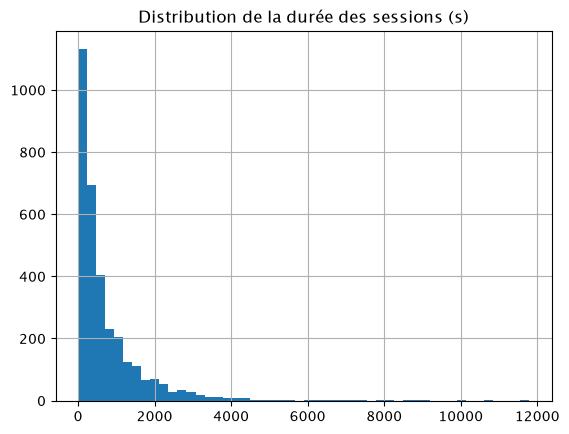

In [12]:

print("Durée moyenne (s) :", sessions['duree'].mean())
print("Durée min (s)     :", sessions['duree'].min())
print("Durée max (s)     :", sessions['duree'].max())
print("Variance          :", sessions['duree'].var())
sessions['duree'].hist(bins=50)
plt.title("Distribution de la durée des sessions (s)")
plt.show()

Actions moyennes : 692.35956084172
Actions min      : 0
Actions max      : 11977
Variance         : 1011782.2584129858


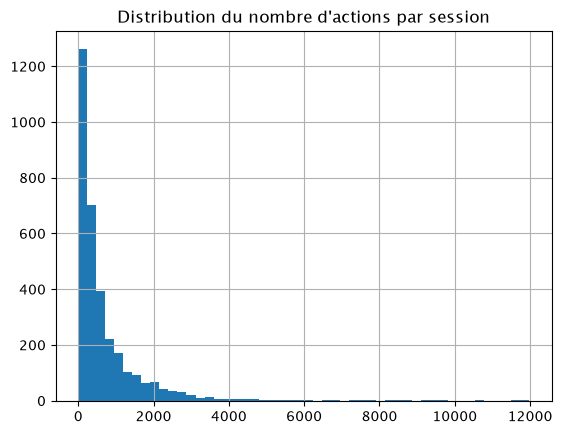

In [13]:
 
print("Actions moyennes :", sessions['nb_actions'].mean())
print("Actions min      :", sessions['nb_actions'].min())
print("Actions max      :", sessions['nb_actions'].max())
print("Variance         :", sessions['nb_actions'].var())
sessions['nb_actions'].hist(bins=50)
plt.title("Distribution du nombre d'actions par session")
plt.show()


Actions/seconde (moyenne des sessions) : 0.9380740426904309
Actions/seconde (global)               : 0.9212655269106064


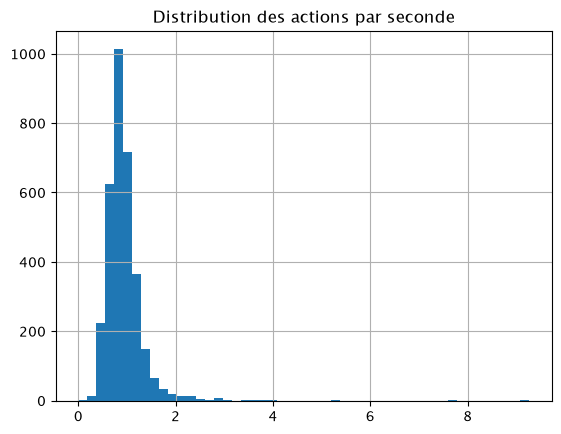

In [14]:

sessions['actions_par_s'] = sessions['nb_actions'] / sessions['duree']
print("Actions/seconde (moyenne des sessions) :", sessions['actions_par_s'].mean())
print("Actions/seconde (global)               :", sessions['nb_actions'].sum() / sessions['duree'].sum())
sessions['actions_par_s'].hist(bins=50)
plt.title("Distribution des actions par seconde")
plt.show()

**Observations**
- Durée et nombre d'actions : distributions très asymétriques à droite (moyenne ≈ 2 × médiane, écart-type > moyenne). La plupart des sessions sont courtes, quelques-unes très longues.
- Les deux histogrammes sont quasi superposés (variances ≈ égales) : durée et nombre d'actions sont redondants.
- Débit quasi constant : ≈ 0,9 action/s, peu de variation d'une session à l'autre, quelques valeurs extrêmes.
- Conséquences : log pour les variables de longueur ; le rythme seul discriminera peu, le contenu des actions sera plus informatif.

In [15]:
@markdown_table(headNtail=True, title="Stats: Y distribution")
def get_Y_stats(df):
    # Nombre de sessions par utilisateur, trié du plus fréquent au moins fréquent
    counts = df["util"].value_counts()
    stats = counts.to_frame("nb_sessions").rename_axis("util")
    stats["pourcentage"] = counts / counts.sum() * 100
    return stats

get_Y_stats(features_train)

#### Stats: Y distribution
|util|nb_sessions|pourcentage|
|--|--|--|
|skm| 75.0| 2.29|
|slq| 71.0| 2.17|
|cjr| 46.0| 1.4|
|flj| 42.0| 1.28|
|hjs| 37.0| 1.13|
|...|...|
|zll| 4.0| 0.12|
|itt| 4.0| 0.12|
|lra| 4.0| 0.12|
|bez| 4.0| 0.12|
|crn| 4.0| 0.12|

count    247.000000
mean      13.275304
std        8.862380
min        4.000000
25%        7.000000
50%       12.000000
75%       16.000000
max       75.000000
Name: count, dtype: float64


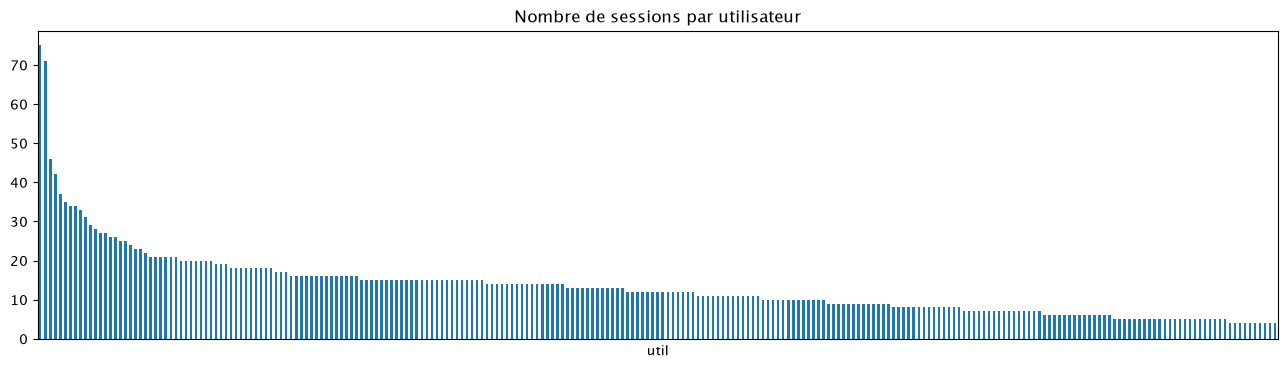

In [16]:
counts = features_train["util"].value_counts()
print(counts.describe())          # moyenne, min, max, quartiles du nb de sessions par utilisateur
counts.plot(kind="bar", figsize=(16, 4), xticks=[])
plt.title("Nombre de sessions par utilisateur")
plt.show()

**Observations**
- 247 utilisateurs, 13,3 sessions en moyenne (médiane 12, min 4, max 75).
- Classes déséquilibrées, queue lourde : deux utilisateurs ont ≈ 70 sessions chacun, un quart des utilisateurs en a 7 ou moins.
- Toujours prédire l'utilisateur le plus fréquent donnerait ≈ 2,3 % d'accuracy : c'est la référence à battre.
- Conséquences : privilégier le F1 macro (les petites classes comptent autant que les grandes) ; validation croisée stratifiée limitée à 4 plis (classe minimale = 4 sessions).

## Construction de caractéristiques

### Traitements préliminaires

En fonction du modèle choisi, différentes étapes de pré-traitement peuvent être nécessaire. Voir https://scikit-learn.org/stable/supervised_learning.html pour des exemples de modèles dans le cas supervisé (notre cas). Quelques exemples : 
- SVMs
- Régression logistiques
- Arbres de décision
- Modèle ensembliste (Random Forest, XGBoost, etc.)
- Réseaux de neurones 

Il faut commencer par se demander s'il y a des valeurs aberrantes (*outliers*) et, le cas échéant, appliquer le traitement approprié (pour le moment vous pouvez à priori les supprimer).

In [17]:
# Règle de Tukey : est aberrante une valeur hors de [Q1 - 1,5 IQR ; Q3 + 1,5 IQR]
import numpy as np

def tukey(x):
    q1, q3 = x.quantile([.25, .75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

n = sessions['nb_actions']
bas, haut = tukey(n)
print(f"Sur le nombre d'actions      : seuils {bas:.0f} / {haut:.0f} -> {(n < bas).sum()} en dessous, {(n > haut).sum()} au-dessus")
bas_log, haut_log = tukey(np.log1p(n))
print(f"Sur log(1 + nombre d'actions) : seuils {np.expm1(bas_log):.0f} / {np.expm1(haut_log):.0f} actions -> "
      f"{(np.log1p(n) < bas_log).sum()} en dessous, {(np.log1p(n) > haut_log).sum()} au-dessus")
print("Nombre d'actions des sessions sous le seuil bas (log) :", sorted(n[np.log1p(n) < bas_log]))

Sur le nombre d'actions      : seuils -845 / 1817 -> 0 en dessous, 297 au-dessus
Sur log(1 + nombre d'actions) : seuils 12 / 10059 actions -> 3 en dessous, 3 au-dessus
Nombre d'actions des sessions sous le seuil bas (log) : [0, 1, 2]


**Observations**
- Sur l'échelle brute, la règle n'est pas adaptée : la distribution est très asymétrique, le seuil bas est négatif et 297 sessions (9 %) seraient « aberrantes ».
- Sur l'échelle log, la règle isole **3 sessions quasi vides** (0, 1 et 2 actions) et 3 sessions de plus de 10 000 actions.

In [18]:
rapides = (sessions['actions_par_s'] > 2).values
print(f"Sessions à plus de 2 actions/s : {rapides.sum()}, réparties sur {features_train.loc[rapides, 'util'].nunique()} utilisateurs")
print("Utilisateurs les plus concernés :", features_train.loc[rapides, 'util'].value_counts().head(3).to_dict())

Sessions à plus de 2 actions/s : 50, réparties sur 36 utilisateurs
Utilisateurs les plus concernés : {'slq': 4, 'nzq': 3, 'azx': 3}


**Observations**
- Les sessions rapides sont dispersées entre de nombreux utilisateurs : ce n'est pas la signature d'un utilisateur en particulier.
- Une partie vient de notre mesure de la durée : les actions après le dernier marqueur `tXX` ne sont pas comptées dans le temps, ce qui gonfle le débit.

**Décisions**
- **On retire du train les sessions de moins de 10 actions** : ce sont les 3 sessions quasi vides désignées par Tukey sur l'échelle log ; elles n'apportent aucune information.
- **On garde les sessions très longues et les sessions rapides** : ce sont de vraies sessions, et avec ~13 sessions par utilisateur, chacune compte. Les représentations les absorbent (fréquences relatives, log et normalisation de la TF-IDF), et l'effet de les retirer est mesuré dans `3_tfidf_modeles.ipynb`.
- **Le test n'est jamais filtré** : chaque session doit recevoir une prédiction.

In [19]:
mask_valides = (sessions['nb_actions'] >= 10).values
print(f"Sessions conservées dans le train : {mask_valides.sum()} / {len(mask_valides)}")

# le test n'est pas filtré : combien de ses sessions passeraient sous le seuil ?
with open('data/test.csv') as f:
    actions_test = [sum(not re.fullmatch(r't\d+', c) for c in ligne.strip().split(',')[1:]) for ligne in f]
print("Sessions du test de moins de 10 actions (gardées) :", sum(n < 10 for n in actions_test), "| minimum :", min(actions_test))

Sessions conservées dans le train : 3276 / 3279


Sessions du test de moins de 10 actions (gardées) : 1 | minimum : 9


## Suite

- `2_features_manuelles_modeles.ipynb` : construction des features, test des modèles, soumission.
- `3_tfidf_modeles.ipynb` : représentation TF-IDF des sessions, modèles testés, soumission finale.